In [1]:
from modeller import *
from modeller.automodel import *

# Initialize environment
env = Environ()
env.io.hetatm = True  # Enable ligand/HETATM coordinate reading
env.io.water = False

# Align target sequence to exact 9HUE coordinates
aln = Alignment(env)
mdl = Model(env, file='9hue.cif')
aln.append_model(mdl, align_codes='9HUE', atom_files='9hue.cif')

glyt1_seq = """MSGGDTRAAIARPRMAAAHGPVAPSSPEQVTLLPVQRSFFLPPFSGATPSTSLAESVLKV
WHGAYNSGLLPQLMAQHSLAMAQNGAVPSEATKRDQNLKRGNWGNQIEFVLTSVGYAVGL
GNVWRFPYLCYRNGGGAFMFPYFIMLIFCGIPLFFMELSFGQFASQGCLGVWRISPMFKG
VGYGMMVVSTYIGIYYNVVICIAFYYFFSSMTHVLPWAYCNNPWNTHDCAGVLDASNLTN
GSRPAALPSNLSHLLNHSLQRTSPSEEYWRLYVLKLSDDIGNFGEVRLPLLGCLGVSWLV
VFLCLIRGVKSSGKVVYFTATFPYVVLTILFVRGVTLEGAFDGIMYYLTPQWDKILEAKV
WGDAASQIFYSLGCAWGGLITMASYNKFHNNCYRDSVIISITNCATSVYAGFVIFSILGF
MANHLGVDVSRVADHGPGLAFVAYPEALTLLPISPLWSLLFFFMLILLGLGTQFCLLETL
VTAIVDEVGNEWILQKKTYVTLGVAVAGFLLGIPLTSQAGIYWLLLMDNYAASFSLVVIS
CIMCVAIMYIYGHRNYFQDIQMMLGFPPPLFFQICWRFVSPAIIFFILVFTVIQYQPITY
NHYQYPGWAVAIGFLMALSSVLCIPLYAMFRLCRTDGDTLLQRLKNATKPSRDWGPALLE
HRTGRYAPTIAPSPEDGFEVQPLHPDKAQIPIVGSNGSSRLQDSRI."""

# Write temporary sequence file
with open('8WFL.seq', 'w') as f:
  f.write('>P1;8WFL\nsequence:8WFL:FIRST:@:LAST:@::::\n' + glyt1_seq + '/*\n')

aln.append(file='8WFL.seq', align_codes='8WFL')

# structural-sequence alignment
aln.align2d()
aln.write(file='glyt1_on_glyt2_verified.ali', alignment_format='PIR')
print('Verified alignment generated successfully: glyt1_on_glyt2_verified.ali')


# Set Knowledge-Based restraints and HETATM transfer
class GlyT1KnowledgeBiased(AutoModel):

  def special_restraints(self, aln):
    rsr = self.restraints

    # 1. Enforce TM1b Alpha-Helix Geometry
    rsr.add(secondary_structure.Alpha(self.residue_range('66:A', '77:A')))

    # 2. Enforce TM6 Helices flanking the unwound binding site
    rsr.add(secondary_structure.Alpha(self.residue_range('261:A', '271:A')))
    rsr.add(secondary_structure.Alpha(self.residue_range('276:A', '291:A')))


a = GlyT1KnowledgeBiased(
    env,
    alnfile='glyt1_on_glyt2_verified.ali',  # Correct verified alignment file
    knowns='9HUE',
    sequence='8WFL',
    assess_methods=(assess.DOPE, assess.normalized_dope),
)

a.starting_model = 1
a.ending_model = 20
a.md_level = refine.slow
a.make()

# Rank Models by DOPE
valid_models = [m for m in a.outputs if m['failure'] is None]
valid_models.sort(key=lambda m: m['DOPE score'])

print('\n' + '=' * 65)
print(f"{'Model Name':<25} | {'DOPE Score':<15} | {'Normalized DOPE (Z)':<15}")
print('=' * 65)
for m in valid_models[:5]:
  norm_z = m.get('normalized DOPE score', 'N/A')
  norm_str = f'{norm_z:.3f}' if isinstance(norm_z, float) else str(norm_z)
  print(f"{m['name']:<25} | {m['DOPE score']:<15.2f} | {norm_str:<15}")
print('=' * 65 + '\n')


                         MODELLER 10.8, 2025/11/04, r13157

     PROTEIN STRUCTURE MODELLING BY SATISFACTION OF SPATIAL RESTRAINTS


                     Copyright(c) 1989-2025 Andrej Sali
                            All Rights Reserved

                             Written by A. Sali
                               with help from
              B. Webb, M.S. Madhusudhan, M-Y. Shen, G.Q. Dong,
          M.A. Marti-Renom, N. Eswar, F. Alber, M. Topf, B. Oliva,
             A. Fiser, R. Sanchez, B. Yerkovich, A. Badretdinov,
                     F. Melo, J.P. Overington, E. Feyfant
                 University of California, San Francisco, USA
                    Rockefeller University, New York, USA
                      Harvard University, Cambridge, USA
                   Imperial Cancer Research Fund, London, UK
              Birkbeck College, University of London, London, UK


Kind, OS, HostName, Kernel, Processor: 4, Darwin Mac 25.6.0 x86_64
Date and time of compilation         : 202

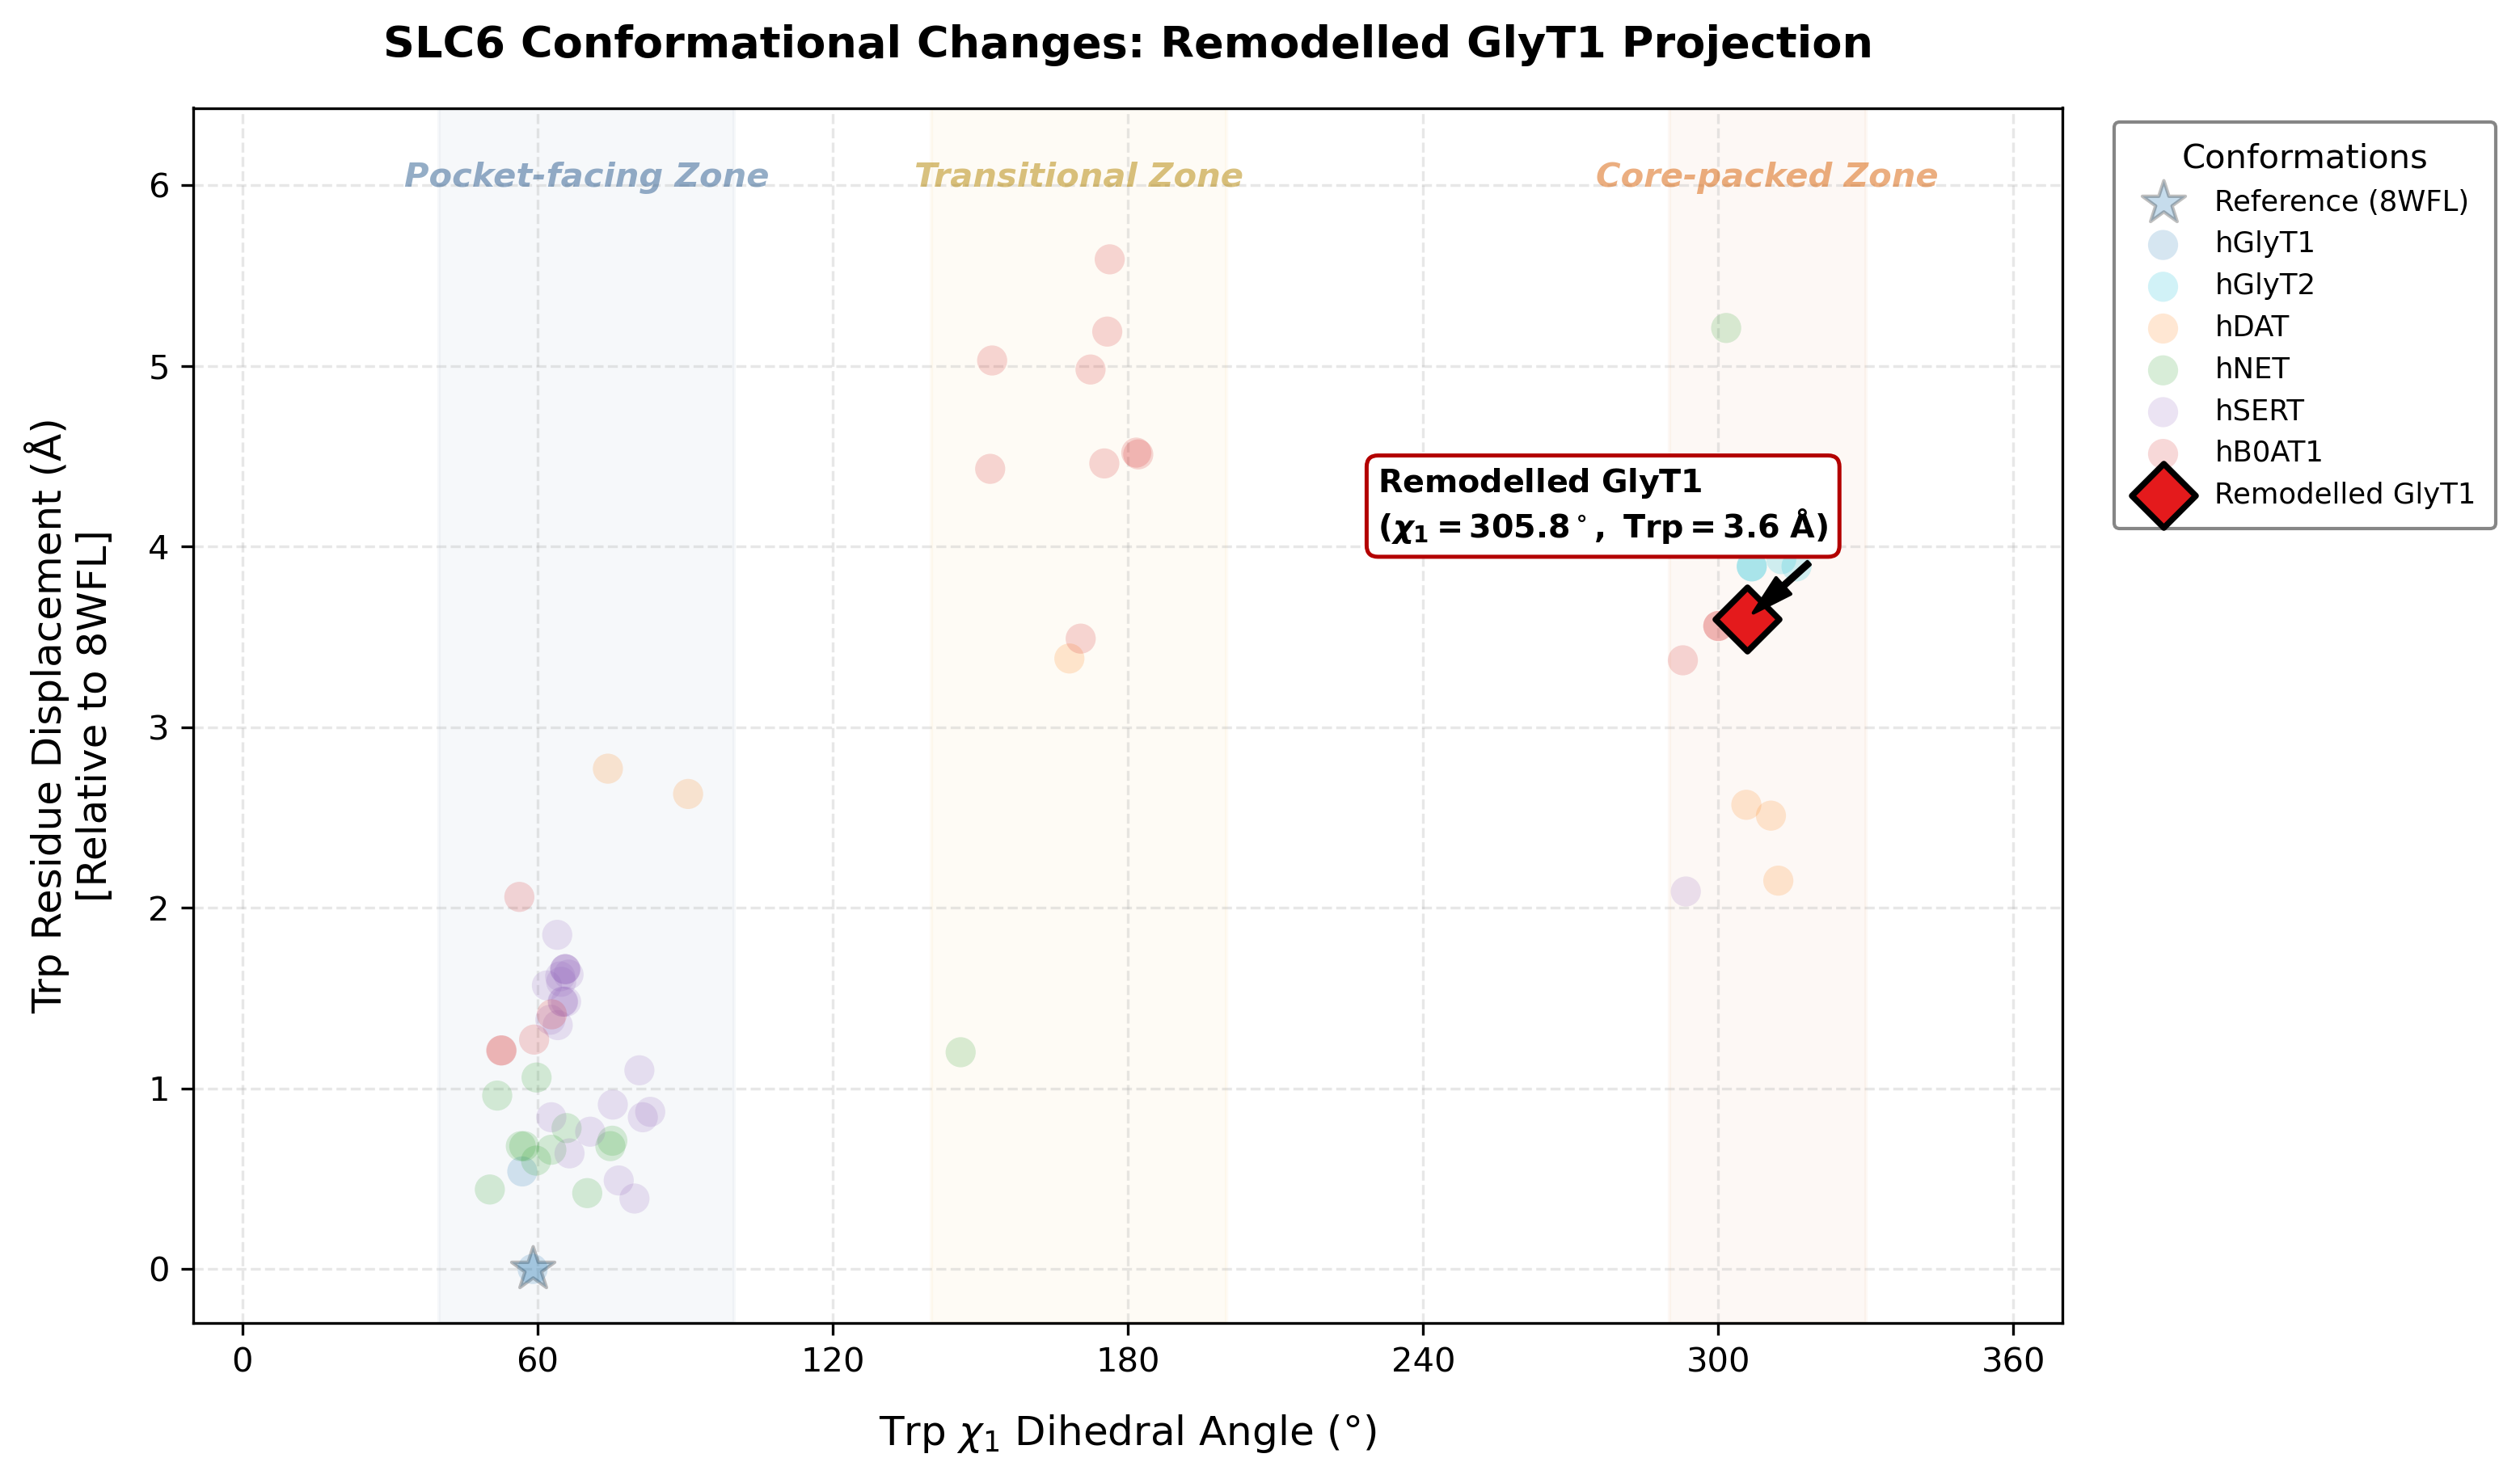

In [ ]:
#### plot for helical displacement as Trp distance

import matplotlib.pyplot as plt
import numpy as np

# Dataset structured by transporter subfamily
data = {
    'hGlyT1': {
        'pdbs': ['8WFL', '8WFK'],
        'chi1': [59.0, 56.9],
        'trp_shift': [0.0, 0.54],
        'color': '#1f77b4',  
    },
    'hGlyT2': {
        'pdbs': ['9HUE', '9HUF', '9W8J', '9W8Q'],
        'chi1': [306.8, 306.8, 315.9, 312.8],
        'trp_shift': [3.89, 3.89, 3.89, 3.93],
        'color': '#00bcd4',  
    },
    'hDAT': {
        'pdbs': ['8VBY', '8Y2G', '9EO4', '9J6R', '9J6S', '9JKM'],
        'chi1': [168.1, 74.3, 312.2, 310.7, 90.6, 305.7],
        'trp_shift': [3.38, 2.77, 2.15, 2.51, 2.63, 2.57],
        'color': '#ff7f0e',
    },
    'hNET': {
        'pdbs': [
            '8WTW',
            '8Y8Z',
            '8Y90',
            '8Y91',
            '8Y92',
            '8Y93',
            '8Y94',
            '8YR2',
            '8Z1L',
            '8ZP1',
            '8ZP2',
            '9K6X',
            '9VWR',
        ],
        'chi1': [
            70.1,
            59.8,
            59.7,
            56.6,
            65.9,
            50.3,
            301.6,
            57.3,
            146.0,
            74.8,
            75.2,
            51.8,
            62.8,
        ],
        'trp_shift': [
            0.42,
            1.06,
            0.6,
            0.68,
            0.78,
            0.44,
            5.21,
            0.68,
            1.2,
            0.68,
            0.71,
            0.96,
            0.66,
        ],
        'color': '#2ca02c',  
    },
    'hSERT': {
        'pdbs': [
            '7TXT',
            '5I6X',
            '5I6Z',
            '5I71',
            '5I73',
            '5I74',
            '5I75',
            '6AWN',
            '6AWO',
            '6AWP',
            '6AWQ',
            '6DZW',
            '6DZY',
            '6VRH',
            '6VRK',
            '6VRL',
            '6W2B',
            '6W2C',
            '7LIA',
            '7LWD',
            '9HCO',
            '9IY7',
            '9VWS',
        ],
        'chi1': [
            81.4,
            64.0,
            61.9,
            64.1,
            65.8,
            66.3,
            64.8,
            65.6,
            65.1,
            64.6,
            65.2,
            62.6,
            293.4,
            66.5,
            62.8,
            75.3,
            65.7,
            65.6,
            80.7,
            70.7,
            82.9,
            76.5,
            79.7,
        ],
        'trp_shift': [
            0.84,
            1.85,
            1.57,
            1.35,
            1.48,
            1.63,
            1.59,
            1.66,
            1.48,
            1.62,
            1.48,
            1.38,
            2.09,
            0.64,
            0.84,
            0.91,
            1.66,
            1.66,
            1.1,
            0.76,
            0.87,
            0.49,
            0.39,
        ],
        'color': '#9467bd',  
    },
    'hB0AT1': {
        'pdbs': [
            '8I92',
            '8I93',
            '6M17',
            '6M18',
            '6M1D',
            '7DWX',
            '7V61',
            '8WBY',
            '8WBZ',
            '9KXT',
            '9KXU',
            '9KXV',
            '9KXW',
            '9KXY',
            '9KXZ',
            '9KY0',
            '9KY1',
        ],
        'chi1': [
            292.8,
            170.4,
            300.0,
            52.6,
            56.3,
            300.0,
            52.7,
            176.3,
            152.4,
            175.8,
            175.2,
            181.7,
            62.9,
            172.4,
            152.0,
            182.1,
            59.3,
        ],
        'trp_shift': [
            3.37,
            3.49,
            3.56,
            1.21,
            2.06,
            3.56,
            1.21,
            5.59,
            5.03,
            5.19,
            4.46,
            4.52,
            1.41,
            4.98,
            4.43,
            4.51,
            1.27,
        ],
        'color': '#d62728',  
    },
}

# Remodeled GlyT1
remodel_chi1 = 305.8  # Replace with exact value from PyMOL run
remodel_shift = 3.6  # Replace with exact value from PyMOL run

fig, ax = plt.subplots(figsize=(10.5, 6.2), dpi=300)

all_shifts = (
    [s for fam in data.values() for s in fam['trp_shift']]
    + [0.0]
    + [remodel_shift]
)
y_max = max(all_shifts) * 1.15

ax.axvspan(40, 100, color='#2b5c8f', alpha=0.04, zorder=1)
ax.axvspan(140, 200, color='#e6ab02', alpha=0.04, zorder=1)
ax.axvspan(290, 330, color='#d95f02', alpha=0.04, zorder=1)

ax.text(
    70,
    y_max * 0.94,
    'Pocket-facing Zone',
    fontsize=10,
    fontstyle='italic',
    color='#2b5c8f',
    alpha=0.5,
    ha='center',
    va='center',
    fontweight='bold',
)
ax.text(
    170,
    y_max * 0.94,
    'Transitional Zone',
    fontsize=10,
    fontstyle='italic',
    color='#b38400',
    alpha=0.5,
    ha='center',
    va='center',
    fontweight='bold',
)
ax.text(
    310,
    y_max * 0.94,
    'Core-packed Zone',
    fontsize=10,
    fontstyle='italic',
    color='#d95f02',
    alpha=0.5,
    ha='center',
    va='center',
    fontweight='bold',
)

ax.scatter(
    [59.0],
    [0.0],
    color='#1f77b4',
    s=180,
    edgecolors='black',
    linewidth=1.0,
    marker='*',
    alpha=0.25,
    zorder=2,
    label='Reference (8WFL)',
)

for family, info in data.items():
  ax.scatter(
      info['chi1'],
      info['trp_shift'],
      color=info['color'],
      marker='o',
      s=80,
      alpha=0.18,  
      edgecolors='none',
      zorder=2,
      label=f'{family}',
  )

ax.scatter(
    [remodel_chi1],
    [remodel_shift],
    color='#e41a1c',
    marker='D', 
    s=180,
    alpha=1.0,  
    edgecolors='black',
    linewidth=1.8,
    zorder=10,
    label='Remodelled GlyT1',
)

annotation_text = (
    r"$\mathbf{Remodelled\ GlyT1}$"
    + "\n"
    + rf"$\mathbf{{(\boldsymbol{{\chi}}_1 = {remodel_chi1}^\circ,\ Trp = {remodel_shift}\ \AA)}}$"
)

ax.annotate(
    annotation_text,
    xy=(remodel_chi1, remodel_shift),
    xytext=(remodel_chi1 - 75, remodel_shift + 0.45),
    arrowprops=dict(
        facecolor="black",
        shrink=0.08,
        width=1.2,
        headwidth=6.5,
        edgecolor="black",
    ),
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="#ffffff",
        edgecolor="#b30000",
        lw=1.2,
    ),
    zorder=11,
)

ax.set_xlabel(r'Trp $\chi_1$ Dihedral Angle (°)', fontsize=12, labelpad=10)
ax.set_ylabel(
    r'Trp Residue Displacement (Å)' + '\n[Relative to 8WFL]',
    fontsize=12,
    labelpad=10,
)
ax.set_title(
    'SLC6 Conformational Changes: Remodelled GlyT1 Projection',
    fontsize=13,
    fontweight='bold',
    pad=15,
)

ax.set_xlim(-10, 370)
ax.set_ylim(-0.3, y_max)
ax.set_xticks([0, 60, 120, 180, 240, 300, 360])
ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    framealpha=0.95,
    fontsize=8.5,
    edgecolor='gray',
    borderpad=0.7,
    title='Conformations',
    title_fontsize='10',
)

plt.tight_layout()
plt.savefig('Remodelled_GlyT1_Conformation_Overlay.png', bbox_inches='tight')
plt.show()